# 10 - Evaluation and Comparison

**Unified comparison of all models and preprocessing variants, for the final conclusions of the entire experiment.**

## Goal of This Notebook

So far, each model-variant notebook (`4.x`-`9.x`) has been evaluated and concluded in isolation.

This notebook combines all of those results in one place and answers questions that cannot be seen from individual notebooks:
1. Which preprocessing variant (baseline/stem/lem/lancaster) proved to be the best for each individual model?
2. Which model is generally the best, considering all 32 combinations?
3. Is the difference between the best models statistically significant (McNemar's test)?
4. How stable is the F1 score of the best models (bootstrap confidence interval)?
5. How do the models compare in terms of training time (GridSearchCV time)?
6. How do the models compare in terms of `.joblib` file size?
7. Do the "lite" versions of Random Forest and KNN justify their existence - and does their trade-off (F1 vs. size) behave the same way for both models?
8. Which model is best relative to the "cost" (file size and training time)?
9. Recall vs. precision

## Note on the Reliability of the Comparison

All results come from a single fixed train/test split (the same for all combinations, `random_state=1`), evaluated once per combination.

This was done for speed and direct comparability (all variants and all models see the same reviews in the train/test split).

## Limitations

A limitation of the experiment is that the variance of the results was not evaluated across multiple different dataset splits or different random seed values.

Therefore, small differences in the achieved F1 score should not be interpreted as evidence of a statistically significant difference between models.

When we refer to the "best" model later in this notebook, this means "the best result we obtained on this specific test set", not a mathematically proven superior model.


In [1]:
import json
import matplotlib.ticker as mticker
import joblib

from pathlib import Path
from IPython.display import display

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.sparse import load_npz
from scipy.stats import binomtest
from sklearn.metrics import f1_score

METRICS_DIR = Path("../results/metrics")
FIGURES_DIR = Path("../results/figures")
MODELS_DIR = Path("../models")
PROCESSED_DIR = Path("../data/processed")

MODEL_ORDER = ["naive_bayes", "logistic_regression", "decision_tree", "random_forest", "lite_random_forest", "knn", "lite_knn", "svm",]
VARIANT_ORDER = ["base", "stem", "lem", "lanc"]

VARIANT_DIRS = {"base": "baseline", "stem": "stemmed",  "lem": "lemmatized", "lanc": "lancaster",}

MODEL_DISPLAY_NAMES = {
    "naive_bayes": "Naive Bayes",
    "logistic_regression": "Logistic Regression",
    "decision_tree": "Decision Tree",
    "random_forest": "Random Forest (heavy)",
    "knn": "KNN (heavy)",
    "svm": "SVM",
    "lite_random_forest": "Random Forest (lite)",
    "lite_knn": "KNN (lite)",
}

VARIANT_DISPLAY_NAMES = {
    "base": "Baseline",
    "stem": "Stemming",
    "lem": "Lemmatization",
    "lanc": "Lancaster",
}

## Helper Function for Loading Saved Models, Test Data, and Predictions


In [2]:
def load_test_data(model_name: str, variant: str):
    """Loads the saved model, test data, and predictions."""
    variant_dir = VARIANT_DIRS[variant]

    model = joblib.load(MODELS_DIR / f"{model_name}_{variant}.joblib")
    X_test = load_npz(PROCESSED_DIR / variant_dir / "X_test.npz")
    y_test = np.load(PROCESSED_DIR / variant_dir / "y_test.npy")
    test_df = pd.read_csv(PROCESSED_DIR / variant_dir / "test.csv")

    y_pred = model.predict(X_test)

    return model, X_test, y_test, test_df, y_pred

## Loading Results

Loads all results into one consolidated DataFrame


In [3]:
rows = []
for metrics_path in sorted(METRICS_DIR.glob("*.json")):
    with open(metrics_path) as f:
        metrics = json.load(f)

    model_name = metrics["model_name"]
    variant = metrics["variant"]

    joblib_path = MODELS_DIR / f"{model_name}_{variant}.joblib"
    if not joblib_path.exists():
        raise FileNotFoundError(f"Missing model file: {joblib_path}")
    size_mb = joblib_path.stat().st_size / (1024 ** 2) if joblib_path.exists() else np.nan

    figure_path = FIGURES_DIR / f"{model_name}_{variant}_confusion_matrix.png"
    if not figure_path.exists():
        raise FileNotFoundError(f"Missing confusion matrix figure: {figure_path}")

    rows.append({
        "model_name": model_name,
        "variant": variant,
        "is_lite": model_name.startswith("lite_"),
        "model_family": model_name.replace("lite_", ""),
        "accuracy": metrics["accuracy"],
        "precision": metrics["precision"],
        "recall": metrics["recall"],
        "f1": metrics["f1"],
        "train_time_seconds": metrics["train_time_seconds"],
        "best_params": metrics["best_params"],
        "size_mb": size_mb,
    })

results_df = pd.DataFrame(rows)

# Sortira prema predefined redosledu (MODEL_ORDER/VARIANT_ORDER)
results_df["model_name"] = pd.Categorical(results_df["model_name"], categories=MODEL_ORDER, ordered=True)
results_df["variant"] = pd.Categorical(results_df["variant"], categories=VARIANT_ORDER, ordered=True)
results_df = results_df.sort_values(["model_name", "variant"]).reset_index(drop=True)

print(f"Loaded {len(results_df)} model-variant combinations")

def format_time(seconds):
    if seconds >= 3600:
        return f"{seconds / 3600:.1f} h"
    if seconds >= 60:
        return f"{seconds / 60:.1f} min"
    return f"{seconds:.0f} s"

results_df[["model_name", "variant", "accuracy", "precision", "recall", "f1", "train_time_seconds", "size_mb"]].style.format(
    {"accuracy": "{:.4f}", "precision": "{:.4f}", "recall": "{:.4f}", "f1": "{:.4f}", "train_time_seconds": format_time, "size_mb": "{:.2f}",})

Loaded 32 model-variant combinations


,model_name,variant,accuracy,precision,recall,f1,train_time_seconds,size_mb
0,naive_bayes,base,0.8858,0.8773,0.8979,0.8875,18 s,1.98
1,naive_bayes,stem,0.8830,0.8759,0.8935,0.8846,13 s,2.04
2,naive_bayes,lem,0.8794,0.8705,0.8925,0.8813,11 s,2.04
3,naive_bayes,lanc,0.8804,0.8709,0.8943,0.8824,19 s,2.09
4,logistic_regression,base,0.9110,0.9025,0.9222,0.9123,2.7 min,0.50
5,logistic_regression,stem,0.9103,0.9046,0.9180,0.9112,2.2 min,0.51
6,logistic_regression,lem,0.9084,0.9012,0.9182,0.9096,2.3 min,0.51
7,logistic_regression,lanc,0.9081,0.9026,0.9158,0.9091,2.6 min,0.52
8,decision_tree,base,0.7333,0.6910,0.8475,0.7613,18.9 min,0.04
9,decision_tree,stem,0.7444,0.7082,0.8344,0.7662,22.0 min,0.04


## Comparison of Preprocessing Variants Within Each Model

Which of the 4 preprocessing variants (baseline/stemmed/lemmatized/Lancaster) gives the best F1 score for each model.

Visualization - grouped bar chart (F1 by model, grouped by variant).

For each model, we rank the 4 variants from best (1) to worst (4) by F1, with information on how many times each rank was achieved by each variant.


model_name,base,stem,lem,lanc,best_variant
naive_bayes,0.8875,0.8846,0.8813,0.8824,base
logistic_regression,0.9123,0.9112,0.9096,0.9091,base
decision_tree,0.7613,0.7662,0.7611,0.7618,stem
random_forest,0.8848,0.8838,0.8801,0.8786,base
lite_random_forest,0.8686,0.8685,0.8666,0.8673,base
knn,0.8200,0.8150,0.8090,0.8118,base
lite_knn,0.8324,0.8292,0.8208,0.8245,base
svm,0.9118,0.9109,0.9102,0.9097,base


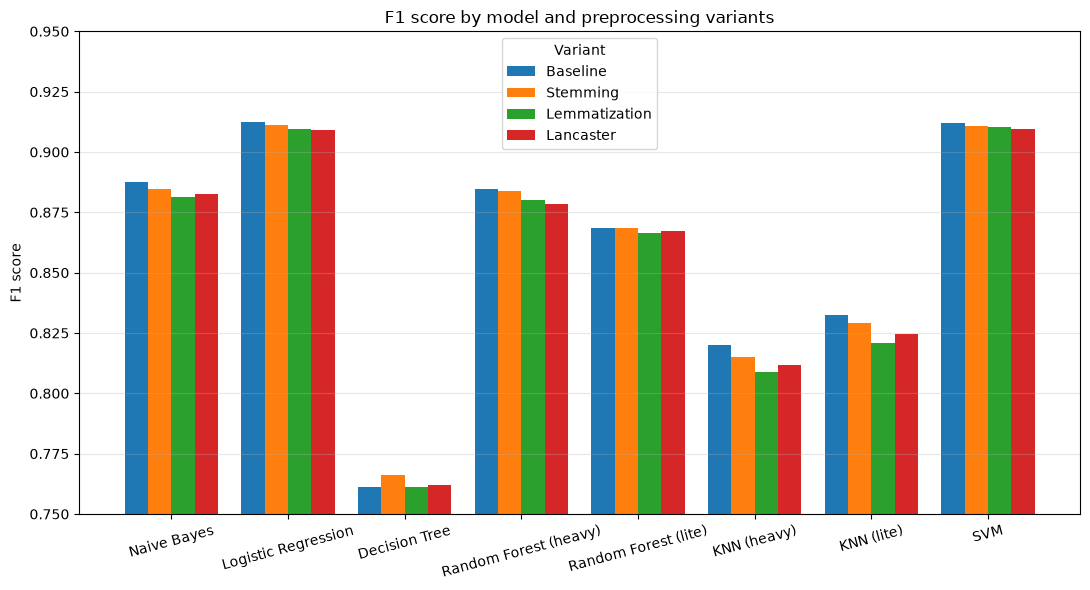

rank,base,stem,lem,lanc
1,7,1,0,0
2,0,7,0,1
3,1,0,3,4
4,0,0,5,3


In [4]:
# Prikaz tabele
variant_pivot = results_df.pivot(index="model_name", columns="variant", values="f1").reindex(index=MODEL_ORDER, columns=VARIANT_ORDER)
variant_pivot["best_variant"] = variant_pivot[VARIANT_ORDER].idxmax(axis=1)

def highlight_best(row):
    is_max = row == row.max()
    return ["background-color: lightgreen; color: black; font-weight: bold;" if v else "" for v in is_max]

variant_pivot = variant_pivot.reset_index()
display(variant_pivot.style.format({c: "{:.4f}" for c in VARIANT_ORDER}).apply(highlight_best, subset=VARIANT_ORDER, axis=1).hide(axis="index"))


# Prikaz bar grafa
n_models = len(MODEL_ORDER)
n_variants = len(VARIANT_ORDER)
bar_width = 0.2
x = np.arange(n_models)

fig, ax = plt.subplots(figsize=(11, 6))
for i, variant in enumerate(VARIANT_ORDER):
    values = variant_pivot[variant].values
    ax.bar(x + i * bar_width, values, width=bar_width, label=VARIANT_DISPLAY_NAMES[variant])

ax.set_xticks(x + bar_width * (n_variants - 1) / 2)
ax.set_xticklabels([MODEL_DISPLAY_NAMES[m] for m in MODEL_ORDER], rotation=15)
ax.set_ylabel("F1 score")
ax.set_ylim(0.75, 0.95)
ax.set_title("F1 score by model and preprocessing variants")
ax.legend(title="Variant")
ax.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


# Rangiranje modela po varijantama
rank_df = results_df.pivot(index="model_name", columns="variant", values="f1").reindex(index=MODEL_ORDER, columns=VARIANT_ORDER)
ranks = rank_df.rank(axis=1, ascending=False).astype(int)

rank_counts = pd.DataFrame({variant: (ranks[variant].value_counts()).reindex([1, 2, 3, 4], fill_value=0) for variant in VARIANT_ORDER})
rank_counts.index.name = "rank"
rank_counts = rank_counts.reset_index()
display(rank_counts.style.hide(axis="index"))

## Comment - Comparison of Variants

For this dataset and this TF-IDF representation, preserving the original word forms appears to be more useful than normalizing them, which does not show a practical advantage.

Baseline (without any normalization) gives the best or tied F1 score for 7 out of 8 models; the only exception is Decision Tree, where stemming slightly outperforms it (a difference of 0.0049 F1). This can be explained by several mechanisms that likely act together:

1. Bigrams change how the effect of normalization manifests
    - `ngram_range=(1,2)` from `3_vectorization.ipynb` means that the model uses both individual words and their neighboring pairs
    - Without normalization, for example, "not disappointing", "not disappointed", and "not disappoint" represent different bigram features
    - Stemming or lemmatisation can reduce these different forms to a common form, aggregating the signal from multiple similar n-grams into a single feature
    - Therefore, it cannot be expected that bigrams alone "do the job" of normalization; they and normalization solve different problems
    - In this experiment, however, aggregating that signal is apparently not enough to compensate for the information lost by transforming the original word forms

2. Normalization removes granularity that can carry sentiment signal
    - When "loved"/"loving"/"love" are reduced to the same token, the model loses the ability to learn a different weight for each form
    - It is possible that these forms are not distributed evenly between positive and negative reviews (e.g. "loved" as the past tense may be associated with stronger praise)
    - Baseline preserves this granularity at the cost of a larger vocabulary

3. A larger, "raw" vocabulary benefits linear models with L2 regularization
    - From the `min_df` analysis in `3_vectorization.ipynb`, we know that there are thousands of terms with moderate (not extreme) class deviations, and that L2 regularization (used by LR and SVM) makes good use of this type of weak signal across a large number of features, rather than relying on a few strong terms
    - Although baseline has the smallest vocabulary of all 4 variants (64.803 terms after filtering, compared to ~66.7-68.4K for the other variants), within its vocabulary baseline has the most unigrams and the fewest bigrams (22.855 unigrams, 41.948 bigrams, compared to ~15.6-22.9k unigrams and ~42-55k bigrams for the other variants)
    - In other words, it has a different unigram/bigram distribution that apparently suits linear models at least equally well

4. The mechanism is different for Decision Tree
    - DT does not combine all features linearly, but instead selects individual splits one by one
    - A smaller, more condensed vocabulary (as a consequence of stemming - fewer unigrams because word variants are merged) probably makes it easier for the tree to find more concentrated, "cleaner" split points, because there are fewer candidates for splits, meaning that the existing signal is not "diluted" across too many similar variants of the same word

Lancaster (more aggressive stemmer):
- It never outperforms Snowball stemming - the hypothesis from `2_preprocessing.ipynb` that more aggressive truncation might help is disproven
- The explanation is probably similar to points 1-2: more aggressive merging of words further reduces granularity without measurable benefit, since most of the benefit from normalization in general has already been "used up" at the more moderate Snowball level.


Lemmatisation is particularly interesting because it is among the worst-performing variants for practically all models:
- One possible explanation is that lemmatisation preserves more linguistic structure than aggressive stemming, but precisely because of this, it does not reduce the number of features as strongly. At the same time, it still changes the original word forms, so it can remove some of the useful signal that baseline preserves. This results in a "compromise" that, in this case, provides an advantage neither in preserving granularity nor in sufficiently reducing the vocabulary
- However, this should be treated as a hypothesis, not as a conclusion that can be proven solely from the F1 results. The results show that lemmatisation is the least useful variant in this experiment, but not the exact reason why


## Overall Best Model

Across all 32 combinations, regardless of the model/variant, which individual combination achieves the best F1 score on the test set.


In [5]:
all_results = results_df.sort_values("f1", ascending=False)[["model_name", "variant", "f1", "accuracy", "precision", "recall", "size_mb"]].reset_index(drop=True)
all_results.insert(0, "rank", range(1, len(all_results) + 1))

def highlight_top10(row):
    rank = row["rank"]
    if rank <= 10:
        # 1 = darkest green, 10 = lightest green
        intensity = (rank - 1) / 9
        green = int(180 + (1 - intensity) * 50)
        return [
            f"background-color: rgb(144, {green}, 144); color: black;"
            for _ in row
        ]
    return [""] * len(row)

display(all_results.style.format({"f1": "{:.4f}", "accuracy": "{:.4f}", "precision": "{:.4f}", "recall": "{:.4f}", "size_mb": "{:.2f}",}).apply(highlight_top10, axis=1).hide(axis="index"))

rank,model_name,variant,f1,accuracy,precision,recall,size_mb
1,logistic_regression,base,0.9123,0.9110,0.9025,0.9222,0.50
2,svm,base,0.9118,0.9107,0.9034,0.9204,0.50
3,logistic_regression,stem,0.9112,0.9103,0.9046,0.9180,0.51
4,svm,stem,0.9109,0.9097,0.9021,0.9198,0.51
5,svm,lem,0.9102,0.9089,0.9007,0.9200,0.51
6,svm,lanc,0.9097,0.9086,0.9030,0.9164,0.52
7,logistic_regression,lem,0.9096,0.9084,0.9012,0.9182,0.51
8,logistic_regression,lanc,0.9091,0.9081,0.9026,0.9158,0.52
9,naive_bayes,base,0.8875,0.8858,0.8773,0.8979,1.98
10,random_forest,base,0.8848,0.8816,0.8645,0.9062,205.58


## Comment - Best Model

Logistic Regression baseline (F1 = 0.9123) and SVM baseline (F1 = 0.9118) occupy the first two places, with a difference of only 0.0005 - practically within the noise of a single train/test split, so they should be treated as tied, rather than as if LR "beat" SVM.

The next 4 places are also LR/SVM, on the other variants (F1 0.9091-0.9112) - the difference between the best and eighth place is only 0.0032, again within the noise of the same split.

The top 8 results (exclusively linear models) should be viewed as one group of practically tied results, not as a ranked list with a clear winner.

The real difference appears only in 9th place, where Naive Bayes base enters (F1 = 0.8875) - as soon as we leave the linear models, F1 drops by around 2 percentage points (from ~0.91 to ~0.89). This is a significant drop considering that the difference within the linear-model group was negligible - Naive Bayes is clearly, measurably weaker than LR/SVM, although it is still the third-best model in the entire experiment.

It makes sense that the difference is most pronounced at this point: Naive Bayes is the only model in the top 3 that does not directly learn a decision boundary (like LR/SVM), but instead relies on the assumption of conditional independence of features, which is known to be incorrect for natural language - yet still "good enough" to keep it ahead of all the other models.

The further drop is even larger and steeper:
- Random Forest heavy, baseline is the best of the remaining "complex" models (F1 = 0.8848), but despite 1500 trees and a huge file (210MB), it remains ~2.75 F1 points behind the best linear model - the additional complexity does not buy anything here compared to Naive Bayes, which is simpler, faster, and smaller.
- KNN and Decision Tree, in their heavy form, are consistently the weakest of all 6 models. Decision Tree has an extremely small file, but its F1 (~0.76) is by far the worst in the entire experiment. KNN heavy is better than Decision Tree but still significantly behind NB/LR/RF/SVM, at the cost of ~1.5GB per variant.

<br>

For the problem of sentiment classification on a TF-IDF representation of this scale, additional model complexity (RF, KNN) does not pay off here - the best and practically tied results come from the two simplest approaches that directly learn a linear boundary (Logistic Regression, Support Vector Machine), while Naive Bayes, although it lags behind them, still outperforms all the remaining, more complex models.


## McNemar's Test – Statistical Significance of the Difference Between the Best Models

So far, we have evaluated differences between models only based on the absolute difference in F1 score.

Here we statistically test whether the difference between two models on the same test set is significant:
- McNemar's test is an exact, binomial test
- It is used to compare two classifiers on the same test examples
- It considers only the examples on which the models disagree and checks whether there is a statistically significant difference in their errors
- Concordant pairs (both correct or both incorrect) do not provide information about the difference between the models, so they are deliberately excluded from the test
- This allows us to determine whether the difference in performance between two models is likely to be real or could be due to chance (noise)
- The result is interpreted using the p-value: if `p < 0.05`, the difference is considered statistically significant


In [6]:
def mcnemar_test(y_true, y_pred_a, y_pred_b, label_a="Model A", label_b="Model B"):
    correct_a = (y_pred_a == y_true)
    correct_b = (y_pred_b == y_true)

    n10 = int(np.sum(correct_a & ~correct_b))  # A tačan, B netačan
    n01 = int(np.sum(~correct_a & correct_b))  # A netačan, B tačan
    n = n10 + n01

    if n == 0:
        print(f"{label_a} i {label_b}: identical predictions - no difference between them.")
        return

    result = binomtest(min(n10, n01), n, p=0.5, alternative="two-sided")

    print(f"{label_a} vs {label_b}")
    print("   Discordant pairs:")
    print(f"      {label_a} correct / {label_b} incorrect = {n10}")
    print(f"      {label_a} incorrect / {label_b} correct = {n01}")
    print(f"   p-value (McNemar, binomial test): {result.pvalue:.4f}")
    print("   -> Statistically significant difference (p < 0.05)" if result.pvalue < 0.05 else "   -> No statistically significant difference (p >= 0.05)")
    print()


# Rank 1 vs rank 2: da li je razlika od 0.0005 F1 (LR vs SVM, baseline) stvarna ili je šum?
_, _, y_test_base, _, lr_base_pred = load_test_data("logistic_regression", "base")
_, _, _, _, svm_base_pred = load_test_data("svm", "base")
mcnemar_test(y_test_base, lr_base_pred, svm_base_pred, "Logistic Regression (base)", "SVM (base)")

# Rank 1 vs rank 9: da li je pad sa grupe linearnih modela na Naive Bayes stvaran?
_, _, _, _, nb_base_pred = load_test_data("naive_bayes", "base")
mcnemar_test(y_test_base, lr_base_pred, nb_base_pred, "Logistic Regression (base)", "Naive Bayes (base)")

Logistic Regression (base) vs SVM (base)
   Discordant pairs:
      Logistic Regression (base) correct / SVM (base) incorrect = 29
      Logistic Regression (base) incorrect / SVM (base) correct = 26
   p-value (McNemar, binomial test): 0.7877
   -> No statistically significant difference (p >= 0.05)

Logistic Regression (base) vs Naive Bayes (base)
   Discordant pairs:
      Logistic Regression (base) correct / Naive Bayes (base) incorrect = 562
      Logistic Regression (base) incorrect / Naive Bayes (base) correct = 312
   p-value (McNemar, binomial test): 0.0000
   -> Statistically significant difference (p < 0.05)



## Comment - McNemar's Test

Logistic Regression (base) vs SVM (base):
- The models have 29 discordant examples in favor of Logistic Regression and 26 in favor of SVM
- McNemar's exact test gives `p = 0.7877`, which is well above the `0.05` threshold. Therefore, there is no statistically significant difference between these two models on the test set used
- In other words, the difference of only `0.0005` F1 between LR baseline and SVM baseline is not large enough to be considered statistically significant

Logistic Regression (base) vs Naive Bayes (base):
- Here, the ratio of discordant pairs is much more pronounced (562 : 312 in favor of Logistic Regression)
- McNemar's test gives `p < 0.0001`, so the difference is statistically significant
- This provides additional evidence that the drop from Logistic Regression baseline to Naive Bayes baseline is much larger than the difference that could be explained by random variation on the test set

This analysis does not prove that the same relationship would necessarily be identical on every possible test set, but it shows that on the test set used, the behavior of LR and SVM does not differ statistically significantly, while the difference between LR and Naive Bayes is clearly statistically significant.


## Bootstrap Confidence Interval for F1 – Reliability of the Best Model's Results

The F1 score has so far been presented as a single point estimate.

Here we additionally assess how stable that estimate is:
- It does not provide just a single F1 estimate, but evaluates how stable that estimate is
- The test set is resampled with replacement multiple times, and F1 is calculated for each resulting sample
- The model is not retrained — the already generated predictions are used
- Based on the obtained F1 values, a (95%) bootstrap confidence interval is calculated
- This allows us to show how reliable a result such as `F1 = 0.9123` is, i.e. how much it could vary under different sampling of the test set


model,variant,f1_point_estimate,ci_lower,ci_upper
Logistic Regression,Baseline,0.9123,0.9060,0.9178
SVM,Baseline,0.9118,0.9055,0.9175
Naive Bayes,Baseline,0.8875,0.8812,0.8938


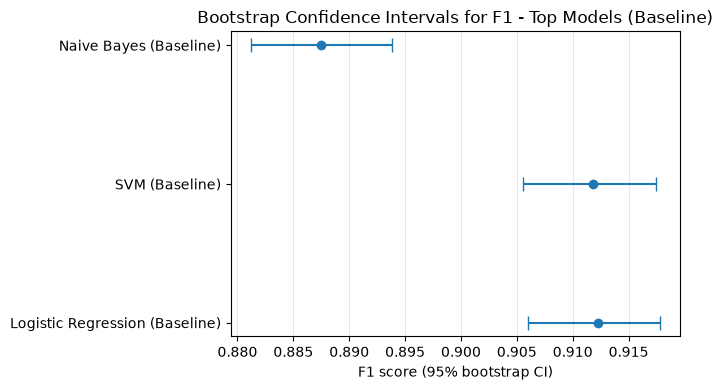

In [7]:
def bootstrap_f1_ci(y_true, y_pred, n_iterations=2000, ci=0.95, random_state=1):
    rng = np.random.RandomState(random_state)
    n = len(y_true)
    f1_scores = np.empty(n_iterations)

    for i in range(n_iterations):
        idx = rng.randint(0, n, n)
        f1_scores[i] = f1_score(y_true[idx], y_pred[idx])

    lower_pct = (1 - ci) / 2 * 100
    upper_pct = (1 - (1 - ci) / 2) * 100
    lower, upper = np.percentile(f1_scores, [lower_pct, upper_pct])
    return f1_scores, lower, upper


models_to_check = [("logistic_regression", "base", lr_base_pred), ("svm", "base", svm_base_pred), ("naive_bayes", "base", nb_base_pred),]

ci_results = []
for model_name, variant, y_pred in models_to_check:
    _, lower, upper = bootstrap_f1_ci(y_test_base, y_pred)
    point_estimate = f1_score(y_test_base, y_pred)
    ci_results.append({
        "model": MODEL_DISPLAY_NAMES[model_name],
        "variant": VARIANT_DISPLAY_NAMES[variant],
        "f1_point_estimate": point_estimate,
        "ci_lower": lower,
        "ci_upper": upper,
    })

ci_df = pd.DataFrame(ci_results)
display(ci_df.style.format({"f1_point_estimate": "{:.4f}", "ci_lower": "{:.4f}", "ci_upper": "{:.4f}"}).hide(axis="index"))

# Vizuelizacija - error bar graf
fig, ax = plt.subplots(figsize=(7, 4))
y_pos = np.arange(len(ci_df))
ax.errorbar(ci_df["f1_point_estimate"], y_pos, xerr=[ci_df["f1_point_estimate"] - ci_df["ci_lower"], ci_df["ci_upper"] - ci_df["f1_point_estimate"]], fmt="o", capsize=5,)
ax.set_yticks(y_pos)
ax.set_yticklabels([f"{r['model']} ({r['variant']})" for r in ci_results])
ax.set_xlabel("F1 score (95% bootstrap CI)")
ax.set_title("Bootstrap Confidence Intervals for F1 - Top Models (Baseline)")
ax.grid(True, axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

## Comment - Bootstrap Confidence Interval

The bootstrap analysis shows that the F1 result of Logistic Regression baseline is relatively stable. For 2,000 bootstrap resamples, a 95% confidence interval of `[0.9060, 0.9178]` was obtained around the point estimate `F1 = 0.9123`.

For SVM baseline, the interval `[0.9055, 0.9175]` was obtained, with `F1 = 0.9118`. The Logistic Regression and SVM intervals almost completely overlap, which is consistent with the result of McNemar's test, which did not show a statistically significant difference between these two models.

Naive Bayes baseline has `F1 = 0.8875` and a 95% bootstrap interval of `[0.8812, 0.8938]`. This interval does not overlap with the intervals of Logistic Regression and SVM, which additionally shows that the difference between Naive Bayes and the best linear models is considerably larger than the expected variation of the F1 estimate itself.

Bootstrap here does not represent retraining the model, nor does it directly test the statistical significance of the difference between models. Its role is to show how stable the estimated F1 is with respect to changes in the test-set sample.


## Training Time Comparison (GridSearchCV Time)

This comparison makes sense, but only on a logarithmic scale - the differences between models are orders of magnitude (from a few seconds to tens of hours), not percentages (a linear scale would show only "one huge and five invisible" bars).

There is no point in comparing the lite versions here because their parameters were selected in advance, and they train only that predefined hyperparameter combination.

Important note: training time is compared only as an approximate metric - it depends on the hardware on which the experiment was run, the grid size for that model (we did not search the same number of hyperparameter combinations everywhere), and the number of CPU cores (`n_jobs=-1`).

Therefore, we do not treat training time as a directly comparable metric like F1 score, but rather as an indicator of practical efficiency and usability.


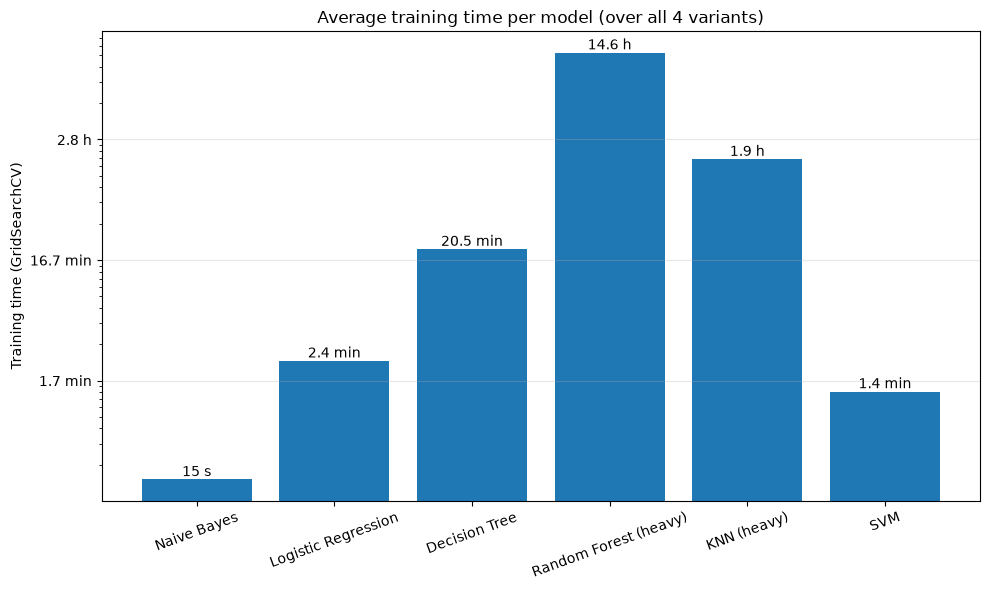

In [8]:
def format_seconds(seconds, pos=None):
    if seconds >= 3600:
        return f"{seconds / 3600:.1f} h"
    if seconds >= 60:
        return f"{seconds / 60:.1f} min"
    return f"{seconds:.0f} s"

time_pivot = results_df[~results_df["is_lite"]].pivot(index="model_name", columns="variant", values="train_time_seconds")
time_pivot = time_pivot.reindex(index=[m for m in MODEL_ORDER if not m.startswith("lite_")], columns=VARIANT_ORDER)
mean_time_per_model = time_pivot.mean(axis=1)

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.bar([MODEL_DISPLAY_NAMES[m] for m in mean_time_per_model.index], mean_time_per_model.values, color="tab:blue")
for bar, value in zip(bars, mean_time_per_model.values):
    ax.text(bar.get_x() + bar.get_width() / 2, value, format_seconds(value), ha="center", va="bottom")

ax.set_yscale("log")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(format_seconds))
ax.set_ylabel("Training time (GridSearchCV)")
ax.set_title("Average training time per model (over all 4 variants)")

plt.xticks(rotation=20)
plt.grid(True, axis="y", which="major", alpha=0.3)
plt.tight_layout()
plt.show()

## Comment - Training Time

Order by speed (from fastest to slowest):

| Model | Order of Magnitude |
|---|---|
| Naive Bayes | a few seconds |
| SVM | ~1.5 minutes |
| Logistic Regression | ~2.5 minutes |
| Decision Tree | ~20 minutes |
| KNN (heavy) | ~2 hours |
| Random Forest (heavy) | **~15 hours** |

The model with the best result (Logistic Regression) is also one of the fastest models, and the same is true for SVM.

On the other hand, Random Forest (heavy) is by far the slowest, but does not achieve a better F1 score than Logistic Regression or SVM.

In this experiment, therefore, the additional time and computational complexity of the heavy models does not pay off relative to the achieved performance.

Note:
- RF and KNN (lite) training times are drastically shorter than their heavy counterparts (e.g. RF lite stem: 44.8 s versus 54,850.7 s for heavy), but this comparison is not directly fair
- The heavy version performs a full GridSearchCV search (a grid of 120 combinations), while the lite version trains only one predefined hyperparameter combination
- Hyperparameter selection for the lite versions was performed earlier through a dedicated coarse/fine search (7.2.x/8.2.x), which also requires time but is not included in this measurement
- Therefore, RF and KNN (lite) results should be interpreted separately from the heavy models


## `.joblib` File Size Comparison

This comparison makes sense, but only on a logarithmic scale (as with the training time comparison) - the differences between models are orders of magnitude (from a few KB to several GB), not percentages (a linear scale would show only "one huge and five invisible" bars).


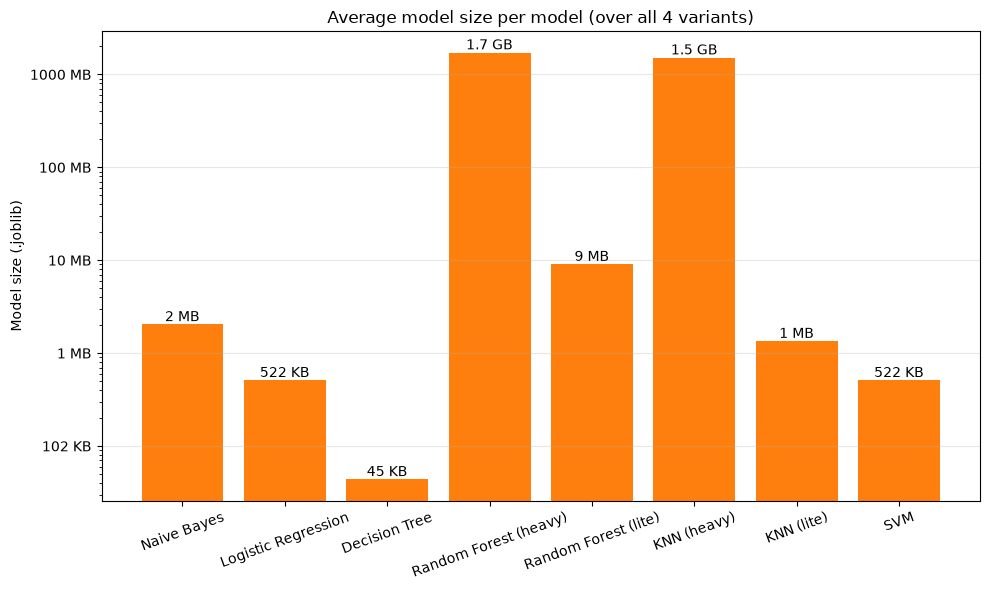

In [9]:
def format_size_mb(value, pos=None):
    if value < 1:
        return f"{value * 1024:.0f} KB"
    elif value < 1024:
        return f"{value:.0f} MB"
    else:
        return f"{value / 1024:.1f} GB"

size_pivot = results_df.pivot(index="model_name", columns="variant", values="size_mb")
size_pivot = size_pivot.reindex(index=MODEL_ORDER, columns=VARIANT_ORDER)
mean_size_per_model = size_pivot.mean(axis=1)

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.bar([MODEL_DISPLAY_NAMES[m] for m in MODEL_ORDER], mean_size_per_model.values, color="tab:orange")
for bar, value in zip(bars, mean_size_per_model.values):
    ax.text(bar.get_x() + bar.get_width() / 2, value, format_size_mb(value), ha="center", va="bottom")

ax.set_yscale("log")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(format_size_mb))
ax.set_ylabel("Model size (.joblib)")
ax.set_title("Average model size per model (over all 4 variants)")

plt.xticks(rotation=20)
plt.grid(True, axis="y", which="major", alpha=0.3)
plt.tight_layout()
plt.show()


## Comment - file size

Order by size (from smallest to largest):

| Model | Order of magnitude |
|---|---|
| Decision Tree | ~50 KB |
| Logistic Regression | ~500 KB |
| SVM | ~500 KB |
| KNN (lite) | ~1 MB |
| Naive Bayes | ~2 MB |
| Random Forest (lite) | ~9 MB |
| KNN (heavy) | ~1.5 GB |
| Random Forest (heavy) | ~1.7 BG |

Decision Tree, Logistic Regression, and SVM are all below 1 MB, which makes them very suitable in terms of the space required to store and share the models.

KNN (heavy) is 1.5 GB across all 4 variants. This is expected because KNN stores the entire reduced train matrix, while the number of components (n_components=5000) does not change between variants. Therefore, the size primarily depends on the number of components and the number of training examples, rather than on the preprocessing variant.

Random Forest (heavy) shows a large difference between variants: around 203–210 MB for base/lem/lanc, but as much as 6.4 GB for stem. This is a direct consequence of GridSearchCV selecting an extreme combination for this variant (max_depth=500, min_samples_leaf=1, n_estimators=2500), which allows the formation of much larger trees.

This segment clearly demonstrates a practical problem with the original RF and KNN models: they are the only models whose file size represents a significant limitation for storing and sharing the results of the work, which further justifies introducing their lite versions.


## Helper Function for Comparing Heavy vs. Lite


In [10]:
def heavy_vs_lite_table(model_family: str) -> pd.DataFrame:
    heavy = results_df[(results_df["model_family"] == model_family) & (~results_df["is_lite"])]
    lite = results_df[(results_df["model_family"] == model_family) & (results_df["is_lite"])]

    merged = heavy.merge(lite, on="variant", suffixes=("_heavy", "_lite"))
    merged["f1_delta"] = merged["f1_lite"] - merged["f1_heavy"]
    merged["f1_delta_pct"] = merged["f1_delta"] / merged["f1_heavy"] * 100
    merged["size_reduction_factor"] = merged["size_mb_heavy"] / merged["size_mb_lite"]

    merged = merged.set_index("variant").reindex(VARIANT_ORDER).reset_index()
    return merged[["variant", "f1_heavy", "f1_lite", "f1_delta", "f1_delta_pct", "size_mb_heavy", "size_mb_lite", "size_reduction_factor"]]

## Detailed Comparison of Heavy vs. Lite - Random Forest


In [11]:
rf_comparison = heavy_vs_lite_table("random_forest")

# Calculate average across all variants
average = rf_comparison.drop(columns="variant").mean(numeric_only=True)
average["size_reduction_factor"] = (average["size_mb_heavy"] / average["size_mb_lite"])
rf_comparison = pd.concat([rf_comparison, pd.DataFrame([{"variant": "Average", **average.to_dict()}])], ignore_index=True)

display(rf_comparison.style.format({
    "f1_heavy": "{:.4f}", "f1_lite": "{:.4f}", "f1_delta": "{:+.4f}", "f1_delta_pct": "{:+.2f}%",
    "size_mb_heavy": "{:.1f}", "size_mb_lite": "{:.1f}", "size_reduction_factor": "{:.1f}x",
}).hide(axis="index"))


variant,f1_heavy,f1_lite,f1_delta,f1_delta_pct,size_mb_heavy,size_mb_lite,size_reduction_factor
base,0.8848,0.8686,-0.0162,-1.84%,205.6,8.2,25.1x
stem,0.8838,0.8685,-0.0152,-1.72%,6255.5,8.7,718.8x
lem,0.8801,0.8666,-0.0135,-1.54%,202.1,9.7,20.9x
lanc,0.8786,0.8673,-0.0113,-1.28%,199.0,9.7,20.6x
Average,0.8818,0.8678,-0.0141,-1.59%,1715.5,9.1,189.4x


## Comment - Random Forest, Heavy vs. Lite

The pattern is consistent across all 4 variants: the relative F1 loss is small and falls within a narrow range (~1.3%–1.8%), while the size reduction factor varies greatly (~21x to ~736x).

This confirms the finding from the `7.2.x` notebooks: a large size reduction factor does not mean that the lite version achieves significantly better F1, but rather primarily depends on how large the heavy version is for the specific variant, i.e. on the selected combination of hyperparameters.

The stem variant has a spectacular reduction factor (736x) because the heavy version was extremely large (6.4 GB), not because the lite version is particularly better in terms of performance.

Random Forest lite represents a justified practical replacement for the heavy version: an ~1.5% F1 loss is a relatively small price to pay for a model that is several times smaller — at least ~20x smaller, and for the stem variant even ~700x smaller.

On average, the lite version loses around 1.59% F1, while the model is on average about 189x smaller (1715.5 MB versus 9.1 MB), showing that a large reduction in size was achieved with a relatively small drop in performance.


## Detailed Comparison of Heavy vs. Lite - KNN


In [12]:
knn_comparison = heavy_vs_lite_table("knn")

# Calculate average across all variants
average = knn_comparison.drop(columns="variant").mean(numeric_only=True)
average["size_reduction_factor"] = (average["size_mb_heavy"] / average["size_mb_lite"])
knn_comparison = pd.concat([knn_comparison, pd.DataFrame([{"variant": "Average", **average.to_dict()}])], ignore_index=True)

display(knn_comparison.style.format({
    "f1_heavy": "{:.4f}", "f1_lite": "{:.4f}", "f1_delta": "{:+.4f}", "f1_delta_pct": "{:+.2f}%",
    "size_mb_heavy": "{:.1f}", "size_mb_lite": "{:.1f}", "size_reduction_factor": "{:.1f}x",
}).hide(axis="index"))

variant,f1_heavy,f1_lite,f1_delta,f1_delta_pct,size_mb_heavy,size_mb_lite,size_reduction_factor
base,0.8200,0.8324,+0.0124,+1.51%,1513.4,1.1,1427.8x
stem,0.8150,0.8292,+0.0143,+1.75%,1513.4,1.4,1052.3x
lem,0.8090,0.8208,+0.0117,+1.45%,1513.4,1.4,1052.3x
lanc,0.8118,0.8245,+0.0127,+1.57%,1513.4,1.4,1052.3x
Average,0.8140,0.8267,+0.0128,+1.57%,1513.4,1.3,1126.3x


## Comment - KNN, Heavy vs. Lite

Here, the situation is qualitatively different from Random Forest: `f1_delta` is positive across all 4 variants. The lite version is not only several times smaller, but also achieves a better F1 score, with a size reduction factor of over 1000x in every case.

This result points to a methodological issue in the original `8.1.x` heavy search:
- n_components was selected based on explained variance, i.e. the amount of variance explained by the components, under the assumption that a larger number of components represents more useful information
- However, explained variance is not the same as relevance for sentiment classification
- TruncatedSVD ranks components according to explained variance, rather than according to how much they contribute to the F1 score
- The additional components may therefore contain information that is not useful for distinguishing positive and negative reviews, and in cosine-based KNN they may even distort the similarity measure between documents

For KNN, the lite approach is not merely a compromise; it demonstrated that selecting n_components based on explained variance was a poor criterion for this classification task.

Directly optimizing the number of components according to the target metric (F1) proved to be not only more effective, but also significantly smaller in terms of memory requirements.

One minor note: for KNN (heavy), precision is slightly higher than recall in 3 out of 4 variants (base/stem/lanc), while for the lite version this relationship is reversed (recall > precision). This represents an additional difference in model behavior, but it is not sufficient as standalone evidence that the additional components are the cause of the poorer behavior — a more detailed analysis would be required to draw such a conclusion.

On average, the lite version achieves a 1.57% higher F1, while the model is approximately 1126x smaller (1513.4 MB versus 1.3 MB), representing an extremely large gain in memory efficiency without a loss in performance.


## F1 vs. "Cost" (File Size and Training Time) - All Models

So far, we have performed the Pareto analysis (best F1 for a given size) only within RF/KNN (heavy vs. lite).

Here, we apply the same principle to ALL 32 combinations at once - which models provide the best F1 for their "cost" (file size), regardless of model type?


In [13]:
def pareto_frontier(df: pd.DataFrame, cost_col: str, score_col: str) -> pd.DataFrame:
    sorted_df = df.sort_values(cost_col).reset_index(drop=True)
    best_so_far = -np.inf
    keep = []
    for _, row in sorted_df.iterrows():
        if row[score_col] > best_so_far:
            keep.append(True)
            best_so_far = row[score_col]
        else:
            keep.append(False)
    return sorted_df[keep]

# Po veličini modela (size_mb) i F1 score-u
pareto_by_size = pareto_frontier(results_df, "size_mb", "f1")
display(pareto_by_size[["model_name", "variant", "f1", "size_mb"]].style.hide(axis="index"))

# Po vremenu treniranja (train_time_seconds) i F1 score-u
pareto_by_time = pareto_frontier(results_df, "train_time_seconds", "f1")
display(pareto_by_time[["model_name", "variant", "f1", "train_time_seconds"]].style.hide(axis="index"))

model_name,variant,f1,size_mb
decision_tree,lem,0.761147,0.022210
decision_tree,base,0.761303,0.040368
decision_tree,stem,0.766165,0.043878
svm,base,0.911823,0.495112
logistic_regression,base,0.912253,0.495250


model_name,variant,f1,train_time_seconds
naive_bayes,lem,0.881349,10.782996
naive_bayes,stem,0.884623,13.401442
naive_bayes,base,0.887499,17.619178
svm,stem,0.910864,59.075599
svm,base,0.911823,95.588396
logistic_regression,base,0.912253,161.816609


## Comment - F1 vs. Cost

### Pareto Front by File Size

The Pareto front shows which combinations of models and preprocessing variants provide an additional improvement in F1 as we move from smaller to larger models (based on the size of the `.joblib` file).

- The front starts with Decision Tree variants, where a small improvement in F1 is achieved with a minimal increase in file size: lem (0.7611, 0.022 MB), base (0.7613, 0.040 MB), and stem (0.7662, 0.044 MB)
- This is followed by a large jump to SVM base (0.9118, 0.495 MB), after which Logistic Regression base achieves the best result of the entire experiment (0.9123) with practically the same file size

After Logistic Regression base, no larger model provides any further improvement in F1, so the Pareto front ends here.

This means that models such as Random Forest and KNN, despite their significantly higher memory requirements, are inferior to Logistic Regression base when F1 and model size are considered simultaneously.

The jump from Decision Tree to SVM/LR is particularly significant: increasing the size from just a few dozen KB to around 0.5 MB results in a very large improvement in F1. After that, further increasing the model size in this experiment does not provide any measurable benefit.

### Pareto Front by Training Time

The Pareto front shows that Naive Bayes provides a very good balance between F1 score and training time, while the largest jump in F1 is achieved by moving to SVM. SVM stem reaches an F1 of 0.9109 in only ~59 s, while Logistic Regression base achieves the best F1 (0.9123), but requires ~162 s of training.

After SVM, additional training time provides only a very small improvement in F1, showing that SVM stem is likely the most attractive Pareto point when training time is the priority, while Logistic Regression base is the choice if maximum F1 is the priority.


## Recall Greater Than Precision

It is worth noting the pattern that occurs across almost all 32 combinations (with the exception of KNN heavy, base/stem/lanc variants).

We demonstrate this using a concrete example of a false positive review based on the best-performing model (Logistic Regression - base).


In [14]:
recall_gt_precision = (results_df["recall"] > results_df["precision"]).sum()
print(f"Combinations where recall > precision: {recall_gt_precision} of {len(results_df)}")

print("\nCombinations where precision > recall:")
display(results_df[results_df["precision"] > results_df["recall"]][["model_name", "variant", "precision", "recall"]].style.format({"precision": "{:.4f}", "recall": "{:.4f}"}).hide(axis="index"))


# Primer false positive recenzije na najboljem modelu
best = all_results.iloc[0]
model_name = best["model_name"]
variant = best["variant"]
model, X_test, y_test, test_df, y_pred = load_test_data(model_name, variant)

false_positive_indices = np.where((y_test == 0) & (y_pred == 1))[0]
if len(false_positive_indices) == 0:
    print("No false positives found.")
else:
    i = false_positive_indices[0]
    if hasattr(model, "predict_proba"):
        positive_probability = model.predict_proba(X_test[i])[0, 1]
    else:
        positive_probability = None

    print(f"\nFirst false positive for {model_name} ({variant}):")
    print(f"True label:      Negative")
    print(f"Predicted label: Positive")
    if positive_probability is not None:
        print(f"Positive probability: {positive_probability:.4f}")
    print("Review:")
    print(test_df.iloc[i]["review_baseline"])

Combinations where recall > precision: 29 of 32

Combinations where precision > recall:


model_name,variant,precision,recall
knn,base,0.8248,0.8154
knn,stem,0.8175,0.8125
knn,lanc,0.8129,0.8107



First false positive for logistic_regression (base):
True label:      Negative
Predicted label: Positive
Positive probability: 0.7650
Review:
early role barbara shelley fact first britain working italy made years old certainly safe say made stunning debut cat girl blondes brunettes get attention always cherish yutte stensgaard lovely auburn haired actress deep voice always exuded intelligence well vulnerability one example village damned screen time much less character husband george sanders sole reason seeing drab update cat people seen great advantage throughout difficult say beauty found even better showcase character apparently sleeps nude exposed luscious bare back awakened also exposed years later rasputin mad monk ravishing gown wears film stunning strapless wonder not see held dress would sure like proof positive barbara shelley poorly written role would defeat actresses rises material makes film consistently watchable real test star power would find soon enough hammer studios

## Comment - Recall vs. Precision

In 29 out of 32 combinations, the model more accurately identifies positive reviews (high recall) than it is "cautious" when labeling them (precision is lower) - in other words, all models (except heavy KNN) are slightly more inclined to incorrectly classify a negative review as positive than vice versa.

This pattern appears across completely different types of models (probabilistic NB, linear LR/SVM, tree-based DT/RF), which suggests that the difference is probably not specific to a particular model type.

One possible explanation is that negative reviews more often contain elements of positive sentiment (e.g. praise for actors, music, or individual scenes before an overall negative conclusion), as well as sarcasm or irony, which can make it more difficult to correctly distinguish them from positive reviews.

<br>

As a concrete illustration of this hypothesis, we can consider the false positive example that was found. Although the review is negative toward the film, most of it is devoted to an explicitly positive description of the actress, with expressions such as "lovely auburn-haired actress" and "exuded intelligence". In contrast, the negative attitude toward the film is expressed briefly, through phrases such as "drab update of Cat People" and "poorly written role".

This balance of positive and negative elements can confuse the model, especially because the negative evaluation refers to the film, while a large portion of the positive sentiment refers to the actress. In this case, Logistic Regression classified the review as positive with a probability of 0.7650, providing a good example of how strong positive signals within a negative review can lead to a false positive classification.


## Final Evaluation Conclusions

Final evaluation conclusions

1. Baseline is the best preprocessing variant for 7 out of 8 models, while for Decision Tree the best variant is stem (F1 = 0.7662). Stemming, lemmatization, and Lancaster stemming generally do not provide improvements over the baseline, and the differences are relatively small. Lancaster, as a more aggressive stemmer, does not outperform Snowball stemming for any model, meaning that the initial hypothesis that more aggressive normalization could produce better results was not confirmed.

2. Overall best model: Logistic Regression, baseline variant (F1 = 0.9123). SVM baseline is practically tied with F1 = 0.9118, while Logistic Regression and SVM occupy the top 8 positions in the ranking. The difference between the two best results is only 0.0005 F1, so it should not be interpreted as particularly significant.

3. Statistical testing of the difference between the best models confirms that Logistic Regression baseline and SVM baseline should not be ranked as clearly different models. The exact McNemar's test gives `p = 0.7877`, meaning that the difference between them is not statistically significant on the test set used. In contrast, the comparison between Logistic Regression baseline and Naive Bayes baseline gives `p < 0.0001`, confirming a statistically significant difference in their errors. This further confirms that the difference between the LR/SVM group and Naive Bayes is real, while the difference within the top of the ranking is not large enough for reliable ranking and can therefore be treated as noise.

4. Bootstrap analysis additionally demonstrates the stability of the F1 results. For Logistic Regression baseline, `F1 = 0.9123` was obtained with a 95% bootstrap confidence interval of `[0.9060, 0.9178]`, while SVM baseline has `F1 = 0.9118` with an interval of `[0.9055, 0.9175]`. Their intervals almost completely overlap, which is consistent with McNemar's test and further supports the conclusion that these two models should be considered practically tied. Naive Bayes baseline has an interval of `[0.8812, 0.8938]`, which does not overlap with the intervals of the LR/SVM models, further supporting the conclusion that there is a larger difference in performance between them.

5. Greater model complexity does not lead to better results. Random Forest and KNN, despite requiring significantly more training time and memory, fail to outperform Logistic Regression and SVM, and are often worse than Naive Bayes as well. Naive Bayes particularly stands out as a highly efficient model: it trains in only a few seconds, occupies around 2 MB, and achieves F1 = 0.8875.

6. The lite versions of Random Forest and KNN produce different results:
   - Random Forest lite represents a classic trade-off: the model size is drastically reduced, with an average loss of around 1.6% F1
   - KNN lite is an even more interesting case: the model is on average more than 1100x smaller, while simultaneously achieving around 1.6% higher F1 than the heavy version
   - This suggests that selecting the number of SVD components based on explained variance was not a good criterion for this classification task

7. The Pareto analysis further confirms the practical advantage of linear models:
   - By model size, Logistic Regression baseline achieves the best F1 with only around 0.5 MB, while no larger model provides any additional improvement
   - By training time, SVM stem represents a very good compromise: F1 = 0.9109 with only around 59 seconds of training, while Logistic Regression baseline requires around 162 seconds to achieve the maximum F1

8. Precision/recall asymmetry is present in 29 out of 32 combinations: recall is higher than precision. This means that the models are generally somewhat more inclined to classify a negative review as positive than vice versa. Since the pattern appears across different types of models, it may be related to characteristics of the data itself, but a more detailed error analysis would be required for a reliable conclusion.

9. Evaluation limitation: all conclusions are based on a single fixed train/test split with 9,917 test reviews. Small differences between the best models, such as Logistic Regression baseline and SVM baseline, should not be interpreted as statistically proven differences, but rather as results obtained on the test set used.
